<a href="https://colab.research.google.com/github/t-vash/build-your-own-llm/blob/main/workshop_agentblazer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Build Your Own LLM - Pretrain, Fine-tune, and Deploy



## Cell 0 - Setup

In [ ]:
!nvidia-smi

import importlib
import torch

packages = [
    "torch", "transformers", "tokenizers", "datasets",
    "peft", "langchain", "chromadb", "gradio", "sentence_transformers"
]

print("\nPackage Versions")
for m in packages:
    try:
        mod = importlib.import_module(m)
        version = getattr(mod, '__version__', '?')
        print(f"OK   {m:<22} {version}")
    except ImportError:
        print(f"FAIL {m:<22} Not Installed")

print("\nActive Execution Device")
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

if torch.cuda.is_available():
    print(f"Allocated GPU: {torch.cuda.get_device_name(0)}")

Thu Sep 24 06:41:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import urllib.request, pathlib
DATA = pathlib.Path("data"); ART = pathlib.Path("artifacts")
DATA.mkdir(exist_ok=True); ART.mkdir(exist_ok=True)

CORPUS = DATA/"corpus.txt"
if not CORPUS.exists():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/"
        "ch02/01_main-chapter-code/the-verdict.txt", CORPUS)
text = CORPUS.read_text(encoding="utf-8")
print(len(text), "characters")
print(text[:2000])

20479 characters
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no great surprise to me to hear that, in the height of his glory, he had dropped his painting, married a rich widow, and established himself in a villa on the Riviera. (Though I rather thought it would have been Rome or Florence.)

"The height of his glory"--that was what the women called it. I can hear Mrs. Gideon Thwing--his last Chicago sitter--deploring his unaccountable abdication. "Of course it's going to send the value of my picture 'way up; but I don't think of that, Mr. Rickham--the loss to Arrt is all I think of." The word, on Mrs. Thwing's lips, multiplied its _rs_ as though they were reflected in an endless vista of mirrors. And it was not only the Mrs. Thwings who mourned. Had not the exquisite Hermia Croft, at the last Grafton Gallery show, stopped me before Gisburn's "Moon-dancers" to say, with tears in her eyes: "We shall not look upon its like again"?

Well!

---
# Module 1 - Subword tokenization
Slides 9–15

### Cell 1 - Why word-level tokenization dies

In [ ]:
import re
vocab = sorted(set(re.findall(r"\w+|[^\w\s]", text.lower())))
print(f"Word-level vocabulary: {len(vocab):,}")
for probe in ["tokenization", "hyperparameter", "Bengaluru"]:
    print(f"  {probe:<16}", "in vocab" if probe.lower() in vocab else "OUT OF VOCABULARY")

Word-level vocabulary: 1,095
  tokenization     OUT OF VOCABULARY
  hyperparameter   OUT OF VOCABULARY
  Bengaluru        OUT OF VOCABULARY


### Cell 2 - Train your own byte-level BPE tokenizer //

In [ ]:
from tokenizers import Tokenizer, decoders, pre_tokenizers, trainers
from tokenizers.models import BPE

SPECIALS = ["<|endoftext|>", "<|pad|>", "<|unk|>"]
tokenizer = Tokenizer(BPE(unk_token="<|unk|>"))
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=True)
tokenizer.decoder = decoders.ByteLevel()

trainer = trainers.BpeTrainer(
    vocab_size=8000, special_tokens=SPECIALS, show_progress=True,
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
tokenizer.train_from_iterator([text], trainer=trainer)

(ART/"tokenizer").mkdir(exist_ok=True)
tokenizer.save(str(ART/"tokenizer"/"tokenizer.json"))
print("vocab size:", tokenizer.get_vocab_size())

vocab size: 2776


### Cell 3 - Wrap it for the Hugging Face stack, and compare against GPT-2

In [ ]:
from transformers import PreTrainedTokenizerFast, AutoTokenizer

tok = PreTrainedTokenizerFast(
    tokenizer_file=str(ART/"tokenizer"/"tokenizer.json"),
    unk_token="<|unk|>", pad_token="<|pad|>",
    eos_token="<|endoftext|>", bos_token="<|endoftext|>")

sample = "Instruction finetuning with LoRA adapters with AgentBlazer, ASEB."
print("ours :", tok.tokenize(sample))
print("gpt2 :", AutoTokenizer.from_pretrained("gpt2").tokenize(sample))
print("round trip:", tok.decode(tok.encode(sample)))

ours : ['ĠI', 'n', 'st', 'ru', 'ction', 'Ġf', 'in', 'et', 'un', 'ing', 'Ġwith', 'Ġ', 'L', 'o', 'R', 'A', 'Ġad', 'ap', 'ter', 's', 'Ġwith', 'ĠA', 'g', 'ent', 'B', 'l', 'az', 'er', ',', 'ĠA', 'S', 'E', 'B', '.']


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

gpt2 : ['Inst', 'ruction', 'Ġfin', 'et', 'uning', 'Ġwith', 'ĠLo', 'RA', 'Ġadapters', 'Ġwith', 'ĠAgent', 'Bl', 'azer', ',', 'ĠA', 'SE', 'B', '.']
round trip:  Instruction finetuning with LoRA adapters with AgentBlazer, ASEB.


---
# Module 2 - Datasets and DataLoaders
Slides 16–22

### Cell 4 - The sliding-window dataset

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

CONTEXT = 128

class NextTokenDataset(Dataset):
    def __init__(self, text, tokenizer, context_length, stride):
        ids = tokenizer.encode(text)
        self.inputs, self.targets = [], []
        for i in range(0, len(ids) - context_length, stride):
            self.inputs.append(torch.tensor(ids[i:i+context_length]))
            self.targets.append(torch.tensor(ids[i+1:i+context_length+1]))
    def __len__(self):  return len(self.inputs)
    def __getitem__(self, i): return self.inputs[i], self.targets[i]

split = int(0.9 * len(text))
train_ds = NextTokenDataset(text[:split], tok, CONTEXT, CONTEXT)
val_ds   = NextTokenDataset(text[split:], tok, CONTEXT, CONTEXT)
train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=8, shuffle=False)
print(len(train_ds), "train windows |", len(val_ds), "val windows")

33 train windows | 3 val windows


### Cell 5 — See the shift-by-one

In [ ]:
x, y = next(iter(train_loader))
print("shapes:", x.shape, y.shape)
print("\nINPUT :", tok.decode(x[0][:20].tolist()))
print("TARGET:", tok.decode(y[0][:20].tolist()))

shapes: torch.Size([8, 128]) torch.Size([8, 128])

INPUT :  more than if I'd never touched a brush."

And his tone told me in a flash
TARGET:  than if I'd never touched a brush."

And his tone told me in a flash that


### Cell 6 — Padding, attention masks and the `-100` trick

In [ ]:
tok.pad_token = tok.pad_token or tok.eos_token
enc = tok(["Short one.", "A noticeably longer example sentence."],
          padding=True, return_tensors="pt")
labels = enc["input_ids"].clone()
labels[enc["attention_mask"] == 0] = -100
print(enc["input_ids"]); print(enc["attention_mask"]); print(labels)

tensor([[ 351,   74, 1905,  378,   16,    1,    1,    1,    1,    1,    1],
        [ 469,  373,  935, 2247, 2375,  481,  374,  610,  770, 1824,   16]])
tensor([[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])
tensor([[ 351,   74, 1905,  378,   16, -100, -100, -100, -100, -100, -100],
        [ 469,  373,  935, 2247, 2375,  481,  374,  610,  770, 1824,   16]])


---
# Module 3 - Causal self-attention

### Cell 7 - Single-head attention, and the weights printed //

In [ ]:
import torch.nn as nn

class CausalSelfAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout=0.0, qkv_bias=False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask",
            torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x, return_weights=False):
        b, n, _ = x.shape
        q, k, v = self.W_query(x), self.W_key(x), self.W_value(x)
        scores = q @ k.transpose(1, 2)
        scores = scores.masked_fill(self.mask.bool()[:n, :n], -torch.inf)
        w = torch.softmax(scores / k.shape[-1] ** 0.5, dim=-1)
        out = self.dropout(w) @ v
        return (out, w) if return_weights else out

torch.manual_seed(123)
ctx, w = CausalSelfAttention(16, 16, 5)(torch.rand(1, 5, 16), return_weights=True)
print(w[0].round(decimals=2))   # note the zeros above the diagonal

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000],
        [0.3300, 0.3400, 0.3300, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2400, 0.0000],
        [0.2000, 0.2100, 0.2000, 0.1900, 0.1900]], grad_fn=<RoundBackward1>)


### Cell 8 - Multi-head attention and the transformer block //

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0
        self.d_out, self.num_heads = d_out, num_heads
        self.head_dim = d_out // num_heads
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask",
            torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        b, n, _ = x.shape
        shape = (b, n, self.num_heads, self.head_dim)
        q = self.W_query(x).view(shape).transpose(1, 2)
        k = self.W_key(x).view(shape).transpose(1, 2)
        v = self.W_value(x).view(shape).transpose(1, 2)
        scores = q @ k.transpose(2, 3)
        scores = scores.masked_fill(self.mask.bool()[:n, :n], -torch.inf)
        w = self.dropout(torch.softmax(scores / self.head_dim ** 0.5, dim=-1))
        out = (w @ v).transpose(1, 2).contiguous().view(b, n, self.d_out)
        return self.out_proj(out)

class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm1 = nn.LayerNorm(cfg["emb_dim"])
        self.att = MultiHeadAttention(cfg["emb_dim"], cfg["emb_dim"],
                                      cfg["context_length"], cfg["drop_rate"],
                                      cfg["n_heads"], cfg["qkv_bias"])
        self.norm2 = nn.LayerNorm(cfg["emb_dim"])
        self.ff = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4*cfg["emb_dim"]), nn.GELU(),
            nn.Linear(4*cfg["emb_dim"], cfg["emb_dim"]), nn.Dropout(cfg["drop_rate"]))

    def forward(self, x):
        x = x + self.att(self.norm1(x))     # residual around attention
        x = x + self.ff(self.norm2(x))      # residual around feed-forward
        return x
print("blocks defined")

blocks defined


### Cell 9 - MiniGPT2 //

In [ ]:
CFG = {"vocab_size": tok.vocab_size, "context_length": CONTEXT, "emb_dim": 192,
       "n_heads": 6, "n_layers": 6, "drop_rate": 0.1, "qkv_bias": False}

class MiniGPT2(nn.Module):
    def __init__(self, cfg=CFG):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop = nn.Dropout(cfg["drop_rate"])
        self.blocks = nn.Sequential(*[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        self.norm_f = nn.LayerNorm(cfg["emb_dim"])
        self.head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)
        self.head.weight = self.tok_emb.weight          # weight tying

    def forward(self, idx):
        _, n = idx.shape
        pos = torch.arange(n, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))
        return self.head(self.norm_f(self.blocks(x)))

    @torch.no_grad()
    def generate(self, idx, max_new_tokens=50, temperature=0.8, top_k=40):
        self.eval()
        for _ in range(max_new_tokens):
            logits = self(idx[:, -self.cfg["context_length"]:])[:, -1, :]
            if top_k:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float("inf")
            probs = torch.softmax(logits / max(temperature, 1e-6), dim=-1)
            idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
        return idx

model = MiniGPT2()
n = sum(p.numel() for p in model.parameters())
print(f"{n:,} parameters (~{n*4/1e6:.1f} MB fp32)")
print("logits:", model(torch.randint(0, CFG["vocab_size"], (2, 12))).shape)

3,223,680 parameters (~12.9 MB fp32)
logits: torch.Size([2, 12, 2776])


**Extra (answer after lunch):** what is the parameter count for `n_heads=12, emb_dim=384`? Predict before you run it.

---
# Module 4a - Launch pretraining
Slides 34–39.

### Cell 10 - The training loop //

In [ ]:
import math, time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Random-guess loss should be about ln(vocab) =", round(math.log(tok.vocab_size), 2))

def batch_loss(model, x, y):
    x, y = x.to(device), y.to(device)
    return torch.nn.functional.cross_entropy(model(x).flatten(0,1), y.flatten())

@torch.no_grad()
def evaluate(model, loader, max_batches=5):
    model.eval(); tot = n = 0
    for i,(x,y) in enumerate(loader):
        if i >= max_batches: break
        tot += batch_loss(model, x, y).item(); n += 1
    model.train(); return tot/max(n,1)

def generate_text(model, prompt, max_new_tokens=50, temperature=0.8, top_k=40):
    ids = torch.tensor([tok.encode(prompt)], device=device)
    return tok.decode(model.generate(ids, max_new_tokens, temperature, top_k)[0].tolist())

Random-guess loss should be about ln(vocab) = 7.93


### Cell 11 - Launch //

In [ ]:
import time
import torch

EPOCHS = 30
model = MiniGPT2(CFG).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.1)
sched = torch.optim.lr_scheduler.OneCycleLR(
    opt, max_lr=3e-4, total_steps=max(EPOCHS * len(train_loader), 1)
)

history, step, t0 = [], 0, time.time()

for epoch in range(EPOCHS):
    model.train()
    for x, y in train_loader:
        opt.zero_grad(set_to_none=True)
        loss = batch_loss(model, x, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched.step()

    val_loss = evaluate(model, val_loader) if 'val_loader' in globals() else loss.item()
    history.append((step, loss.item(), val_loss))
    step += 1

    model.eval()
    print(f"\nsample after epoch {epoch + 1}")
    print(generate_text(model, prompt="The painter ", max_new_tokens=30))

ART.mkdir(parents=True, exist_ok=True)
torch.save(model.state_dict(), ART / "mini_gpt2.pt")
print(f"\ndone in {(time.time() - t0) / 60:.1f} min -> {ART / 'mini_gpt2.pt'}")

NameError: name 'MiniGPT2' is not defined

---
# Module 4b - Read the results
Slides 40–44

### Cell 12 - Loss curve, samples, and what temperature does

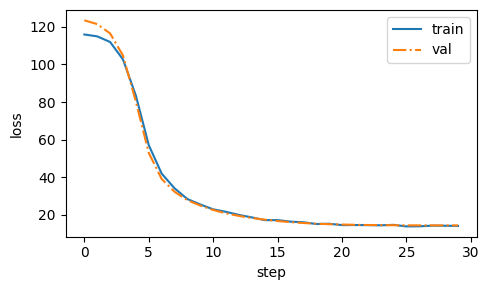


[T=0.2]  The painter,,,,,,,,,,,,,,,,,, I I I I I I I I I I I I I I I I I I I I I I I I I I I I I I I I

[T=0.8]  The painter mur mur mur mur mur mur mur mur mur mur mur mur mur mur mur mur mur mur mur mur mur mur mur murearedearedeared super super,airairarette own ownarettearettearettearettearettearettearettearettearettearettearettearettearettearettearette

[T=1.3]  The painter
 Gisburn.AreAreAreAreAreAreAre felt the. fo fotipliedtiplied..

 to of_ thither thitheram had had ofDes, of1 own own her her I a it mur mur mur murusing swept swept swept


In [ ]:
import matplotlib.pyplot as plt
steps, tr, va = zip(*history)
plt.figure(figsize=(5,3))S
plt.plot(steps, tr, label="train"); plt.plot(steps, va, "-.", label="val")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.tight_layout(); plt.show()

for T in (0.2, 0.8, 1.3):
    print(f"\n[T={T}] {generate_text(model, 'The painter', temperature=T)}")

It writes word-shaped English and knows **nothing**. Module 5 fixes instruction-following; Module 6 fixes knowledge.

---
# Module 5 - LoRA fine-tuning
Slides 45–54

### Cell 13 - Watch DistilGPT2 ignore an instruction

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer
BASE = "distilgpt2"

hf_tok = AutoTokenizer.from_pretrained(BASE)
hf_tok.pad_token = hf_tok.eos_token
base = AutoModelForCausalLM.from_pretrained(BASE).to(device).eval()

def format_prompt(e):
    t = ("Below is an instruction that describes a task. "
         "Write a response that appropriately completes the request."
         f"\n\n### Instruction:\n{e['instruction']}")
    if e.get("input"): t += f"\n\n### Input:\n{e['input']}"
    return t + "\n\n### Response:\n"

def ask(model, prompt, max_new_tokens=60):
    enc = hf_tok(prompt, return_tensors="pt").to(device)
    out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=True,
                         temperature=0.7, top_p=0.9, pad_token_id=hf_tok.eos_token_id)
    return hf_tok.decode(out[0], skip_special_tokens=True)[len(prompt):].strip()

probe = format_prompt({"instruction":"Rewrite the sentence using a simile.",
                       "input":"The car is very fast."})
print("BEFORE:", ask(base, probe))

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

BEFORE: The car is very fast.
### Output:
The car is very fast.
### Output:
The car is very fast.
### Output:
The car is very fast.
### Output:
The car is very fast.
### Output:
The car is very fast


### Cell 14 - Instruction data in the Alpaca format

In [ ]:
import json
from datasets import Dataset

IDATA = DATA/"instruction-data.json"
if not IDATA.exists():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/rasbt/LLM-workshop-2024/main/"
        "06_finetuning/instruction-data.json", IDATA)
data = json.loads(IDATA.read_text())
print(len(data), "entries\n")
print(format_prompt(data[50]) + data[50]["output"])

rows = [{"text": format_prompt(e) + e["output"] + hf_tok.eos_token} for e in data]
cut = int(0.85*len(rows))

def tokenize(b):
    out = hf_tok(b["text"], truncation=True, max_length=256, padding="max_length")
    out["labels"] = [[(t if m==1 else -100) for t,m in zip(i,a)]
                     for i,a in zip(out["input_ids"], out["attention_mask"])]
    return out

train_i = Dataset.from_list(rows[:cut]).map(tokenize, batched=True, remove_columns=["text"])
eval_i  = Dataset.from_list(rows[cut:]).map(tokenize, batched=True, remove_columns=["text"])

1100 entries

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Identify the correct spelling of the following word.

### Input:
Ocassion

### Response:
The correct spelling is 'Occasion.'


Map:   0%|          | 0/935 [00:00<?, ? examples/s]

Map:   0%|          | 0/165 [00:00<?, ? examples/s]

In [ ]:
pip install --upgrade peft transformers accelerate torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 832.9/832.9 kB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 70.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 94.6 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0
  Attempting uninstall: transformers
    Found existing installation: transformers 5.16.1
    Uninstalling transformers-5.16.1:
      Successfully uninstalled transformers-5.16.1
  Attempting uninstall: accelerate
    Found existing installation: accelerate 1.14.0
    Uninstalling accelerate-1.14.0:
      Successfully uninstalled accelerate-1.14.0
  Attempting uninstall: peft
    Found existing installation: peft 0.20.0
    Uninstalling peft-0.20.0:
      Successfully uninstalled peft-0.20.0


### Cell 15 - LoRA with PEFT: `W_updated = W + A·B`//

In [ ]:
from peft import LoraConfig, TaskType, get_peft_model
from transformers import AutoModelForCausalLM

lora_cfg = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=32,
    lora_alpha=64,
    lora_dropout=0.05,
    target_modules=["c_attn", "c_proj"],
    bias="none"
)

model_lora = get_peft_model(
    AutoModelForCausalLM.from_pretrained(BASE), lora_cfg
)
model_lora.print_trainable_parameters()

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

trainable params: 1,622,016 || all params: 83,534,592 || trainable%: 1.9417


/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2631: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  


### Cell 16 - Train one epoch, then compare

In [ ]:
from transformers import Trainer, TrainingArguments
import torch

args = TrainingArguments(
    output_dir=str(ART / "lora-ckpt"),
    num_train_epochs=3,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=2,
    learning_rate=3e-4,
    warmup_steps=10,
    logging_steps=25,
    eval_strategy="epoch",
    save_strategy="no",
    report_to=[],
    fp16=torch.cuda.is_available()
)

trainer = Trainer(
    model=model_lora,
    args=args,
    train_dataset=train_i,
    eval_dataset=eval_i
)

trainer.train()

model_lora.save_pretrained(str(ART / "distilgpt2-lora"))
hf_tok.save_pretrained(str(ART / "distilgpt2-lora"))

print("\nAFTER:", ask(model_lora.to(device).eval(), probe))
!du -sh artifacts/distilgpt2-lora

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 

**Extra** set `r=32` and `target_modules=["c_attn","c_proj"]`. Does the extra capacity buy anything?

---
# Module 6 - Retrieval-augmented generation
Slides 55–63

### Cell 17 - Build a knowledge base and chunk it

In [ ]:
KB = DATA/"knowledge_base"; KB.mkdir(exist_ok=True)
(KB/"workshop.md").write_text('''# Build Your Own LLM workshop
The AgentBlazer workshop runs on September 24 from 08:00 to 16:00 in Krishna Hall,
first floor. Full-day OD is provided. It is open to students of all years and
requires no prior experience. The stack is PyTorch, Hugging Face, LangChain,
ChromaDB and Gradio, and everything runs on a standard laptop.''')
(KB/"lora.md").write_text('''# LoRA
LoRA freezes the original weights and learns two small matrices A and B whose
product approximates the weight update: W_updated = W + A @ B. At rank 8 on a
768-dimensional projection it trains about 12,000 parameters instead of 590,000,
and the saved adapter is a few megabytes rather than gigabytes.''')

from langchain_community.document_loaders import DirectoryLoader, TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

docs = DirectoryLoader(str(KB), glob="**/*.md", loader_cls=TextLoader).load()
chunks = RecursiveCharacterTextSplitter(
    chunk_size=500, chunk_overlap=80,
    separators=["\n\n","\n",". "," ",""]).split_documents(docs)
print(len(docs), "documents ->", len(chunks), "chunks")
print(chunks[0].page_content[:200])

### Cell 18 - Embed into ChromaDB and retrieve

In [ ]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma

emb = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2",
                            encode_kwargs={"normalize_embeddings": True})
store = Chroma.from_documents(chunks, emb, collection_name="byol",
                              persist_directory=str(ART/"chroma"))
retriever = store.as_retriever(search_kwargs={"k": 3})

question = "What time does the workshop end and where is it held?"
hits = retriever.invoke(question)
for i, d in enumerate(hits, 1):
    print(f"{i}. [{d.metadata['source'].split('/')[-1]}] {d.page_content[:120]}...")

### Cell 19 - Ground the prompt, ask again

In [ ]:
RAG_TEMPLATE = '''Answer the question using only the context below.
If the context does not contain the answer, say you do not know.

### Context:
{context}

### Question:
{question}

### Answer:
'''

print("WITHOUT retrieval:", ask(model_lora, format_prompt({"instruction": question})))

prompt = RAG_TEMPLATE.format(
    context="\n\n---\n\n".join(d.page_content for d in hits), question=question)
print("\nWITH retrieval   :", ask(model_lora, prompt, max_new_tokens=120))

**Extra:** upload your own notes into `data/knowledge_base/`, re-run Cells 17–19, and tune `chunk_size` and `k`.

---
# Module 7 - Ship it
Slides 64–69

### Cell 20 - The three-tab Gradio app

In [ ]:
import gradio as gr

def tab_tokenize(t):
    ids = tok.encode(t)
    return (f"{len(t)} chars -> {len(ids)} tokens",
            [[i, s.replace("\u0120","_"), n] for i,(s,n) in
             enumerate(zip(tok.convert_ids_to_tokens(ids), ids))])

def tab_generate(prompt, which, n_tokens, temp):
    if which.startswith("MiniGPT2"):
        return generate_text(model, prompt, int(n_tokens), float(temp))
    return ask(model_lora, format_prompt({"instruction": prompt}), int(n_tokens))

def tab_rag(q, k):
    hits = store.as_retriever(search_kwargs={"k": int(k)}).invoke(q)
    ctx = "\n\n---\n\n".join(d.page_content for d in hits)
    ans = ask(model_lora, RAG_TEMPLATE.format(context=ctx, question=q), 120)
    src = "\n\n".join(f"**{i}. {d.metadata['source'].split('/')[-1]}**\n\n{d.page_content}"
                       for i,d in enumerate(hits,1))
    return ans, src

with gr.Blocks(title="Build Your Own LLM", theme=gr.themes.Soft()) as demo:
    gr.Markdown("# Build Your Own LLM\nEverything from today, behind one interface.")
    with gr.Tab("1. Tokenizer"):
        ti = gr.Textbox(label="Text", value="LoRA adapters on a laptop.", lines=2)
        tb = gr.Button("Tokenize", variant="primary")
        ts, tt = gr.Markdown(), gr.Dataframe(headers=["#","token","id"])
        tb.click(tab_tokenize, [ti], [ts, tt])
    with gr.Tab("2. Generate"):
        gp = gr.Textbox(label="Prompt", value="Rewrite using a simile: the car is very fast.", lines=2)
        gw = gr.Radio(["MiniGPT2 (ours)", "DistilGPT2 + LoRA"], value="DistilGPT2 + LoRA", label="Model")
        gn = gr.Slider(16, 256, value=120, step=8, label="Max new tokens")
        gt = gr.Slider(0.1, 1.5, value=0.7, step=0.05, label="Temperature")
        gb = gr.Button("Generate", variant="primary"); go = gr.Textbox(label="Output", lines=8)
        gb.click(tab_generate, [gp, gw, gn, gt], [go])
    with gr.Tab("3. Ask your documents"):
        rq = gr.Textbox(label="Question", value="What time does the workshop end?")
        rk = gr.Slider(1, 6, value=3, step=1, label="Chunks")
        rb = gr.Button("Ask", variant="primary")
        ra, rs = gr.Textbox(label="Answer", lines=6), gr.Markdown()
        rb.click(tab_rag, [rq, rk], [ra, rs])

demo.launch(share=True)

In [ ]:
!pip install qrcode[pil] -q

import qrcode
from IPython.display import display

demo.launch(share=True)

if demo.share_url:
    print("Encoding URL:", demo.share_url)
    img = qrcode.make(demo.share_url)
    display(img)
else:
    print("Share URL not generated yet. Make sure share=True is set.")

---
## You're done

In `artifacts/` you now have your tokenizer, your pretrained checkpoint, your LoRA
adapter and your Chroma index — and a public URL serving all four.

**Take it further:** index your semester notes · fine-tune on a tone you like ·
push this folder to a Hugging Face Space · swap DistilGPT2 for a 1B model on Colab.

Feedback QR on the closing slide. Thanks for building with us.